# 06 · Monitoring and verdicts

*What happens to a verdict after it's issued and who watches the checks.*

Notebook 05 ran the checks once a month on the planted data (the way a scheduled job would) and recorded a few metrics per run. That answered "how fast is a fault caught". This notebook asks the questions that come after a QA system has been running for a while.

First **do verdicts change?** A verdict issued in March was made with only the data up to March. Once more data arrives the same hour can be judged differently because normals are better known, neighbours have reported and a wobble has turned out to be a lasting shift. If verdicts move anyone who trained on last month's verdicts trained on a different dataset than anyone training today.

Second **who watches the checks?** Every check fires at some background rate. When that rate jumps it means a new fault, unusual weather or a check that has quietly changed. A **control chart** draws a band around each rate from its own recent history and raises an alert when it leaves.

Third **what happens to a human review?** Notebook 05 checked 30 alarms by hand. Those labels are worth keeping as data beside the verdicts so they change what a user sees without erasing what the machine said.

Everything here runs on the real station data and not the planted copy.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from wxlab import stations as st, reference as ref, faults as fl, qa, monitoring as mon

plt.rcParams["figure.dpi"] = 80
REF_DIR, QA_DIR = Path(DATA_DIR) / "reference", Path(DATA_DIR) / "qa"

reference = ref.load(REF_DIR / "hrrr")
model_elev = pd.read_parquet(REF_DIR / "hrrr_model_elevation.parquet").set_index("station_id").model_elevation_m
hourly = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", years=range(2021, 2025))
matched = ref.match(hourly, reference, model_elev).dropna(subset=["hrrr_air_temperature"])
older = st.load_standardized(Path(DATA_DIR) / "standardized" / "isd", station_ids=matched.station_id.unique(), years=range(2015, 2021))
clim = qa.climatology(older)
points = pd.read_parquet(REF_DIR / "station_points.parquet")
dups = fl.duplicate_pairs(matched)
nbrs = qa.neighbours(points, dups)

final = pd.read_parquet(QA_DIR / "real_flags.parquet")       # one run over all four years (notebook 05)
print(f"{len(matched):,} station-hours at {matched.station_id.nunique()} stations")

5,249,635 station-hours at 165 stations


## Step 1 · Run the checks month by month on real data

`qa.monitor` replays history. For each month it runs every check on all data up to the end of that month and keeps only that month's verdicts. That's what a user would have seen on the first day of the next month. It takes a while (48 runs over a growing table) so the result is cached.

In [3]:
mon_path, monflags_path = QA_DIR / "monitoring_real.parquet", QA_DIR / "monitoring_flags_real.parquet"
if mon_path.exists():
    metrics, asof = pd.read_parquet(mon_path), pd.read_parquet(monflags_path)
else:
    metrics, asof = qa.monitor(matched, clim, nbrs)
    metrics.to_parquet(mon_path); asof.to_parquet(monflags_path)
metrics["month"] = pd.PeriodIndex(metrics["month"], freq="M")
print(len(metrics), "monthly runs")

48 monthly runs


## Step 2 · How often do verdicts change?

Join each hour's verdict as first issued with its verdict in hindsight (the single run over all four years). Rows are the first verdict and columns where it ended up.

In [4]:
j = mon.verdict_churn(asof, final)
print(f"{(j['first'] != j['final']).mean():.2%} of station-hours changed verdict")
print(j.change.value_counts(normalize=True).round(4).to_dict())
mon.churn_table(j).round(3)

1.71% of station-hours changed verdict
{'same': 0.9829, 'tightened': 0.0146, 'relaxed': 0.0025}


final,pass,suspect,quarantine
first,,,
pass,0.985,0.015,0.000
suspect,0.286,0.704,0.010
quarantine,0.007,0.035,0.957


Text(0.0, 1.0, "Share of each month's verdicts that changed in hindsight")

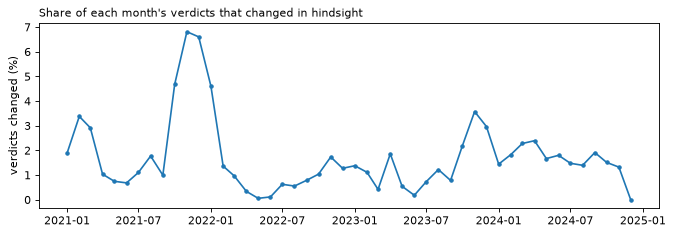

In [5]:
# When in the record do changes happen? Early months have the least history behind them.
j["month"] = j.time.dt.tz_localize(None).dt.to_period("M")
rate = j.assign(changed=j["first"] != j["final"]).groupby("month").changed.mean()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(rate.index.to_timestamp(), rate * 100, marker=".")
ax.set_ylabel("verdicts changed (%)"); ax.set_title("Share of each month's verdicts that changed in hindsight", loc="left", fontsize=10)

Most verdicts hold. About 1.7% of station-hours changed and quarantine is the most stable: 96% of hours quarantined at the time are still quarantined in hindsight. The movement is between pass and suspect and it mostly goes one way. Hindsight finds *more* to be suspicious of, not less.

The peak in late 2021 says why. Those changes come almost entirely from the day-level shift detectors which fire on about five times as many hours in hindsight. They compare each station with its own seasonal cycle (estimated from the median of each day of the year across all years). A run in autumn 2021 had only that autumn to estimate autumn from so an unusual stretch looked normal by definition. With four years of autumns the same stretch stands out. Verdicts made early in a record are made against a baseline that's still being learned.

This happens in production too. NOAA rebuilds GHCN-Daily every week and warns that a value's quality flag can change as late data arrives and it versions every full reprocessing ([NOAA GHCN-Daily](https://webarchive.library.unt.edu/web/20201218051500/https://www.ncdc.noaa.gov/ghcn-daily-description)).

The lesson for a pipeline is that a verdict is a function of the data *and* of when it was computed. Storing verdicts with the run that produced them (a version) instead of overwriting them is what lets a model name the exact verdicts it trained on.

## Step 3 · A control chart for every check

Each monthly run recorded how often each check fired. A band from the previous 12 months (median ± 4 robust standard deviations) shows when a rate leaves its normal range. Using only earlier months means a month never judges itself.

In [6]:
rate_cols = [c for c in metrics.columns if c.startswith("rate_")] + ["coverage", "stations_quarantined"]
cc = mon.control_chart(metrics, rate_cols, floor=1e-4)
alerts = cc[cc.alert]
print(len(alerts), "alerts over", metrics.month.nunique(), "months")
alerts.groupby("metric").month.apply(lambda m: ", ".join(str(x) for x in m)).to_frame("months")

42 alerts over 48 months


,months
metric,
coverage,2022-10
rate_changepoint,2022-11
rate_climatology,"2022-04, 2022-05, 2022-06, 2023-08, 2023-12, 2..."
rate_neighbour,"2022-02, 2023-10, 2023-11, 2023-12, 2024-01, 2..."
rate_physical,2024-03
rate_reference,"2023-09, 2023-12, 2024-01"
rate_shift,"2022-10, 2022-11, 2022-12, 2023-01"
rate_stuck,"2022-12, 2023-02, 2023-03, 2023-10, 2023-12, 2..."
rate_timing,"2022-02, 2023-10, 2023-11, 2024-11"


Text(0.0, 1.0, 'Monthly check rates with their control bands (red = alert)')

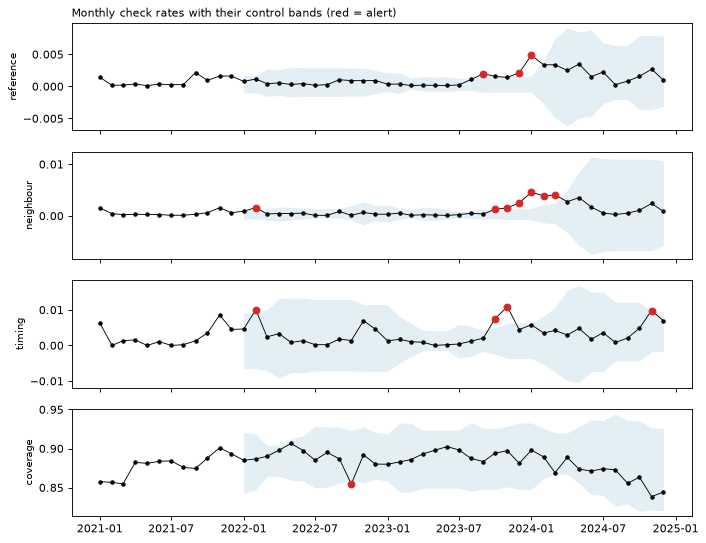

In [7]:
show = ["rate_reference", "rate_neighbour", "rate_timing", "coverage"]
fig, axes = plt.subplots(len(show), 1, figsize=(10, 8), sharex=True)
for ax, c in zip(axes, show):
    d = cc[cc.metric == c]; x = d.month.dt.to_timestamp()
    ax.fill_between(x, d.lower, d.upper, color="tab:blue", alpha=0.12, lw=0)
    ax.plot(x, d.value, marker=".", color="k", lw=0.8)
    ax.scatter(x[d.alert], d.value[d.alert], color="tab:red", zorder=3)
    ax.set_ylabel(c.replace("rate_", ""), fontsize=9)
axes[0].set_title("Monthly check rates with their control bands (red = alert)", loc="left", fontsize=10)

The clearest alerts are the run from late 2023 into 2024 when the reference and neighbour rates rise together. One station drives almost all of it. The naval airfield whose sensor reported 2 °F on and off (notebook 03) produced over 500 alarm hours on each check in those four months. A rate chart that knows nothing about stations still noticed one broken station because a fault that loud moves the whole network's rate.

Other alerts are noisier. Rare checks like the stuck check fire a handful of times a month so their band is narrow and a few extra hours trip it. 42 alerts in 48 months is too many for anyone to act on. In practice alerts are grouped into episodes and checks this rare are watched by counts (with limits from a Poisson model rather than a rolling MAD).

An alert on a check rate is a different question from an alert on a station. It asks whether the QA system still behaves as it did. A check whose rate drifts slowly upward over a year may be fine or may be reacting to something that changed upstream (like a new model version in the reference). That's why the rates themselves are worth monitoring.

## Step 4 · Reviews as data

The 30 alarms reviewed by hand in notebook 05 become override records: station, month, label, the action it implies, the reason, who reviewed and when. They're joined beside the verdicts as a separate column. The automatic verdict stays as it was so it can still be scored and a review can be undone by deleting a row.

In [8]:
review = pd.read_csv(Path("..") / "docs" / "real-flag-review.csv", dtype={"station_id": str})
overrides = mon.overrides_from_review(review, reviewer="owner", reviewed_at="2026-11-08")
reviewed = mon.apply_overrides(final, overrides)
print(overrides.action.value_counts().to_dict())
q0, q1 = (reviewed.verdict == "quarantine").sum(), (reviewed.reviewed_verdict == "quarantine").sum()
print(f"quarantined hours: {q0:,} automatic → {q1:,} after review")
overrides.head()

{'lift_to_suspect': 20, 'confirm': 5, 'none': 5}
quarantined hours: 4,611 automatic → 4,525 after review


,station_id,month,label,action,reason,reviewer,reviewed_at
0,72585093228,2023-11,fault,confirm,drops to about -18 °C for a few hours while ne...,owner,2026-11-08 00:00:00+00:00
1,99847999999,2024-10,weather,lift_to_suspect,October 2024 heat wave; the pier runs hotter t...,owner,2026-11-08 00:00:00+00:00
2,72381603159,2021-02,weather,lift_to_suspect,a few hours out of step with a fast temperatur...,owner,2026-11-08 00:00:00+00:00
3,72392793110,2022-02,weather,lift_to_suspect,isolated hours during a fast change; timing di...,owner,2026-11-08 00:00:00+00:00
4,99401299999,2022-02,weather,lift_to_suspect,a few hours during a warm spell; station and n...,owner,2026-11-08 00:00:00+00:00


The 20 "weather" reviews lift only 86 of 4,611 quarantined hours. Weather false alarms are short (a few hours each) while the big blocks of quarantine are real faults that review confirms. Review improves the rows it touches and nothing else. The other months keep their automatic verdicts.

The next step in a real system is to turn repeated review outcomes into rules. Notebook 05's false alarms fell into a few weather patterns (coastal heat waves in offshore wind, local winds HRRR times an hour off, fog). A rule that recognises one pattern changes the checks which then needs the whole recall and precision evaluation again on planted and real data. Reviews feed the rules. They don't replace the evaluation.

## What I learned

- **Verdicts change and hindsight is stricter.** 1.7% of verdicts changed once more data arrived and most went from pass to suspect. Training sets built at different times differ so reproducing a model needs dataset versions.
- **Early verdicts rest on a baseline still being learned.** The churn peak in late 2021 came from a seasonal cycle estimated from too little data.
- **A network-wide chart can catch one station.** The naval airfield alone pushed two check rates out of their bands.
- **A control band uses only earlier months.** Including the current month would widen the band and could hide its own alert.
- **Reviews sit beside the automatic verdict.** The checks can still be scored on what they said and a review can be undone. Reviewing false alarms barely changed the data because they're short.

**Still open:** how long should a live system wait before it calls a month's verdicts final?